## Анализ данных о Нобелевских лауреатах

### **Контекст проекта**
В этом задании мы будем работать с датасетом о лауреатах Нобелевской премии. Ваша задача — распарсить и проанализировать эти данные, ответив на ключевые вопросы о закономерностях вручения премий, демографических характеристиках лауреатов и исторических тенденциях.

### **Этап 1: Подготовка данных**

**Задача:** На этом этапе вам надо собрать структурированный список словарей с информацией о лауреатах и призах. Приведем начало нужного нам датасета.

``` {code:python}
[{'id': '745',
  'name': 'A. Michael Spence',
  'gender': 'male',
  'birth_year': 1943,
  'country_birth': 'USA',
  'country_now': 'USA',
  'prizes_relevant': [{'prize_amount': 10000000,
    'prize_amount_adjusted': 15547541,
    'award_year': 2001,
    'category_en': 'Economic Sciences',
    'prize_status': 'received'}],
  'type_': 'person'},
 {'id': '102',
  'name': 'Aage N. Bohr',
  'gender': 'male',
  'birth_year': 1922,
  'country_birth': 'Denmark',
  'country_now': 'Denmark',
  'prizes_relevant': [{'prize_amount': 630000,
    'prize_amount_adjusted': 4304697,
    'award_year': 1975,
    'category_en': 'Physics',
    'prize_status': 'received'}],
  'type_': 'person'}]
  ```

Поскольку информация о лауреатах-людях и лауреатах-организациях структурирована по-разному, а также из-за того, что часть полей в json могут отсутстввовать, необходимо реализовать функции для процессинга словарей, которые будут достаточно обобщаемыми для обоих типов данных.

**Что нужно сделать:**

На входе информация о конкретном лауреате представляет из себя кучу вложенных друг в друга словарей. Из этой структуры нам надо получить плоский словарь вида {atribute: value}, где atribute --- это один из небольшого множества интересных нам атрибутов. При этом в исходном файле 
1. пути к атрибутам могут иметь разную длину
2. атрибуты могут отсутствовать
3. атрибуты могут нуждаться в дополнительной обработке (например, поле id в исходных словарях записано как строка.)

Поскольку наивная реализация такого обработчика оказывается довольно громоздкой, вам нужно создать файл json_dict_processing.py, в котором реализован высокоуровневый функционал для решения задачи "обработать вложенный json-словарь"

Главное требование к интерфейсу: 
по (вложенному) словарю о лауреате и конфигу (см ниже) надо получить плоский словарь вида {atribute: value}.

Достичь этого можно, например, таким набором функций

* `extract_nested_value(obj, keys)` - извлекает значение из вложенных структур данных по цепочке ключей

* `process_dictionary_with_config(dictionary, config)` - обрабатывает один словарь согласно словару-конфигу (формат конфига см ниже.)

* `process_list_of_dicts_with_config(list_of_dicts, config)` - обрабатывает список словарей, эта функция нужна чтобы обработать список призов.

* `create_processor(config, list_processor=False)` - создает готовый процессор с предзагруженной конфигурацией. В случае, если list_processor == True, внутрь процессора подается process_list_of_dicts_with_config, иначе process_dictionary_with_config.

**Замечание насчет последней функции.**

Планируемое применение этой функции примерно такое:
`laureate_processor = create_processor(PERSON_CONFIG, list_processor=False)`

То есть, create_processor возвращает функцию, которая реализует функционал process_dictionary_with_config но с уже заполненным конфигом. Это повышает читаемость кода и снижает риск перепутать конфиги из-за дублирования кода.


Помимо этого нужно создать файлы-конфиги для данных по призам, лауреатам-людям, и лауреатам-организациям.

КОНФИГ для функций process_dictionary_with_config и process_list_of_dicts_with_config имеет следующий вид
```python
  {'атрибут_который_берем_сырым': ['путь', 'к', 'данным'],  # или
  'атрибут_который_нужно_обработать': (['путь', 'к', 'данным'], функция_обработки)}
  ```
В случае, если атрибут можно взять в итоговый датасет сырым, в values() словаря-конфига будет список path_list.
Если же атрибут еще надо обработать, для него в поле config[attribute] будет tuple вида (path_list, function).

Примеры атрибутов, которые можно взять сырыми: имя, размер приза. Примеры атрибутов, которые нужно обработать: год вручения приза (в сырых данных есть только полная дата, записанная как строка)

После того, как будет создан core.py, создайте конфиги laureates_configs.py и prizes_configs.py

Постарайтесь провалидировать код с помощью assert-ов, вызываемых в ноутбуке или в .py-файлах.

пример использования: 

assert 1 == True

**Валидация**

В вашем случае assert должен взять простой словарик с одним вложенным полем и какой-нибудь конфиг-файл.
Также убедитесь, что при обработке данных собственно по лауреатам в них нет странностей (смотрите ниже) 

**Атрибуты для ПРИЗА (CONFIG_PRIZE, prizes_configs.py)**

- `prize_amount` - сумма приза → `prizeAmount`
- `prize_amount_adjusted` - скорректированная сумма приза → `prizeAmountAdjusted`
- `award_year` - год вручения приза (преобразуется в целое число) → `awardYear`
- `category_en` - категория на английском → `category.en`
- `prize_status` - статус приза → `prizeStatus`

**Атрибуты для ЧЕЛОВЕКА-ЛАУРЕАТА (CONFIG_PERSON, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - имя лауреата → `knownName.en`
- `gender` - пол → `gender`
- `birth_year` - год рождения (извлекается из даты) → `birth.date`
- `country_birth` - страна рождения → `birth.place.country.en`
- `country_now` - текущая страна → `birth.place.countryNow.en`
- `prizes_relevant` - список призов лауреата → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Атрибуты для ОРГАНИЗАЦИИ-ЛАУРЕАТА (CONFIG_ORG, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - название организации → `orgName.en`
- `founded_year` - год основания (извлекается из даты) → `founded.date`
- `country_founded` - страна основания → `founded.place.country.en`
- `country_now` - текущая страна → `founded.place.countryNow.en`
- `prizes_relevant` - список призов организации → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Вспомогательные функции:**

- `process_year(year_string)` - извлекает год из строки даты (формат "YYYY-MM-DD"). Функция находится в файле laureates_configs.py
- `prize_processor()` - создает процессор для обработки списков призов. Функция находится в файле prizes_configs.py
- `person_processor()` - создает процессор для данных о людях-лауреатах. Функция находится в файле laureates_configs.py
- `org_processor()` - создает процессор для данных об организациях-лауреатах. Функция находится в файле laureates_configs.py

In [3]:
import json

with open("laureates.json", encoding="utf-8") as file:
    laureates = json.load(file)

In [4]:
from json_dict_processing import process_dictionary_with_config
from laureates_configs import CONFIG_PERSON

assert process_dictionary_with_config(
    {"birth": {"date": "1943-11-07"}}, CONFIG_PERSON
) == {
    "id": None,
    "name": None,
    "gender": None,
    "birth_year": 1943,
    "country_birth": None,
    "country_now": None,
    "prizes_relevant": None,
}

In [5]:
from laureates_configs import process_orgs, process_persons


def get_laureate_data(laureate):
    if "knownName" in laureate:
        result = process_persons(laureate)
        result["type_"] = "person"
    elif "orgName" in laureate:
        result = process_orgs(laureate)
        result["type_"] = "org"

    return result


laureates_data = []

for laureate in laureates["laureates"]:
    laureates_data.append(get_laureate_data(laureate))



### **Этап 2: EDA лауреатов**

EDA или Exploratory Data Analysis - первый шаг при работе с любыми данными.

Чтобы начать работать с этой секцией, проведите проведите чисто технический анализ собранных данных.

1. Сколько всего записей?
2. Все ли значения полей заполнены?
3. Если нет, сколько пропусков в каждом из полей? Выведите ответ на этот вопрос в формате `{'field_name': missing_values}`. А какая доля пропусков?
5. Каковы максимальные и минимальные значения поля id и каким годам награждения они соответствуют? Есть ли записи с повторяющимися id? Есть ли пары айди, которые в отсортированном массиве айдишников различаются более, чем на один? 

При реализации ответов на эти вопросы, пользуйтесь теми же принципами, что описаны выше. Можете начать с плохого хакерского кода, однако в таком случае в маркдауне пропишите, как будете его обобщать и разносить по функциям и модулям. (об этом ниже)

В основном EDA пользуйтесь аккуратным кодом, разбитым на функции и файлы.

#### Технический анализ

In [6]:
from dataset_helpers import (
    filter_records, group_by_attributes, aggregate_groups,
    count_missing_values, missing_value_shares,
    duplicate_values, find_integer_gaps, unique_records,
)
from aggregations import count_records, mean_value, median_value, maximum_value, top_n
from atribute_manager import add_attribute
from laureates_configs import CONFIG_PERSON, CONFIG_ORG
from prizes_configs import CONFIG_PRIZE

print("Всего записей:", count_records(laureates_data))

Всего записей: 1028


Пропуски отдельно для людей и организаций.

In [7]:
for type_, label, config in [
    ("person", "Люди", CONFIG_PERSON),
    ("org", "Организации", CONFIG_ORG),
]:
    records = filter_records(laureates_data, lambda row: row["type_"] == type_)
    fields = list(config) + ["type_"]
    counts = count_missing_values(records, fields)
    missing = {field: count for field, count in counts.items() if count > 0}
    print(f"\n{label}:")
    if missing:
        shares = missing_value_shares(records, fields)
        print("Пропуски:", missing)
        print("Доли:", {field: round(shares[field], 4) for field in missing})
        print("В остальных полях пропусков нет.")
    else:
        print("Пропусков нет.")


Люди:
Пропуски: {'country_birth': 3, 'country_now': 3}
Доли: {'country_birth': 0.003, 'country_now': 0.003}
В остальных полях пропусков нет.

Организации:
Пропуски: {'founded_year': 1, 'country_founded': 4, 'country_now': 4}
Доли: {'founded_year': 0.0357, 'country_founded': 0.1429, 'country_now': 0.1429}
В остальных полях пропусков нет.


In [8]:
all_prizes = [
    prize for row in laureates_data
    for prize in (row["prizes_relevant"] or [])
]
counts = count_missing_values(all_prizes, CONFIG_PRIZE)
missing = {field: count for field, count in counts.items() if count > 0}
print("Премии:")
if missing:
    shares = missing_value_shares(all_prizes, CONFIG_PRIZE)
    print("Пропуски:", missing)
    print("Доли:", {field: round(shares[field], 4) for field in missing})
    print("В остальных полях пропусков нет.")
else:
    print("Пропусков нет.")

Премии:
Пропусков нет.


In [9]:
min_id = min(row["id"] for row in laureates_data)
max_id = maximum_value(laureates_data, "id")
for label, id_value in [("Минимальный ID", min_id), ("Максимальный ID", max_id)]:
    for row in filter_records(laureates_data, lambda row: row["id"] == id_value):
        award_years = sorted({prize["award_year"] for prize in row["prizes_relevant"]})
        print(f"{label}: {id_value}; лауреат: {row['name']}; годы награждения: {award_years}")

Минимальный ID: 1; лауреат: Wilhelm Conrad Röntgen; годы награждения: [1901]
Максимальный ID: 1070; лауреат: Michael Woodford; годы награждения: [2026]


In [10]:
print("\nПовторяющиеся ID (ID: число записей):", duplicate_values(laureates_data, "id"))
print("Пары соседних уникальных ID с разницей больше 1:", find_integer_gaps(laureates_data, "id"))


Повторяющиеся ID (ID: число записей): {}
Пары соседних уникальных ID с разницей больше 1: [(6, 8), (93, 95), (169, 172), (255, 257), (468, 470), (503, 505), (520, 523), (541, 543), (569, 571), (590, 592), (594, 596), (597, 600), (610, 613), (615, 617), (631, 633), (635, 637), (645, 647), (655, 657), (783, 786), (787, 789), (858, 861), (896, 903), (949, 958), (1009, 1011)]



Поскольку это курс по Python, а не по статистике или визуализации данных, мы не задаем жесткие рамки того, что вы должны проанализировать.
Однако это отличная возможность представить себя в роли разработчика базы данных или, например, библиотеки pandas.

В коде нужно соблюдать следующие правила:

1. должны быть реализованы  несколько способов работы с данными (среднее/медианное/максимальное значение метрики, количество примеров, вывод топ-N объектов по значению метрики).
2. анализ выбранных вами тем должен включать в себя анализ метрик в тотале, по категориям и в динамике по годам или десятилетиям.
3. проанализировать стоит 2-3 темы. Вы можете использовать темы ниже или взять свои.
2. вывод ноутбука должен быть понятен обывателю. Это может быть визуализация в matplotlib/seaborn. Сопровождайте вывод markdown-ячейками с вашими  мыслями, пояснениями и инсайтами, которые удалось извлечь.
3. Нельзя использовать pandas и numpy, но можно вдохновляться их интерфейсом и функционалом при дизайне ваших функций.


Из пункта 2 следует, что вам придется работать не только с атрибутами лауреатов, но и самих призов.
Информацию о призах нужно доставать и записывать как атрибут уже лауреата. Функции, работающие с призами (например, факт того, что лауреат отказался от какого-то из призов) можно реализовать в ноутбуке, но если вы создаете более общие вспомогательные функции, выносите их в отдельные модули.

Мы рекомендуем следующую структуру кода:

* `dataset_helpers.py` в котором реализованы фильтрация списка словарей (плоских) по условиям (аналог sql-ного where), а также аналог sql-ного групбая. А также функция для применения агрегаций к списку словарей
* `aggregations.py` в котором реализованы функции расчета среднего/медианы/других эвристик и мб вывод топ n-значений по какой-то метрике.
* `atribute_manager.py` в котором реализован переиспользуемый интерфейс для добавления (и мб удаления) полей.

Замечание насчет group-by. 

На игрушесном примере она может работать примерно так:
```
    Входные данные: [
        {'name': 'Alice', 'country': 'USA', 'age': 25},
        {'name': 'Bob', 'country': 'UK', 'age': 30},
        {'name': 'Charlie', 'country': 'USA', 'age': 25}
    ]
    
    group_by_attributes(data, ['country', 'age']) → {
        ('USA', 25): [
            {'name': 'Alice', 'country': 'USA', 'age': 25},
            {'name': 'Charlie', 'country': 'USA', 'age': 25}
        ],
        ('UK', 30): [
            {'name': 'Bob', 'country': 'UK', 'age': 30}
        ]
    }
```

Замечание насчет agregations.py
1. Агрегации соответственно должны применяться к спискам вида [
    {'name': 'Alice', 'country': 'USA', 'age': 25},
    {'name': 'Charlie', 'country': 'USA', 'age': 25}
]
2. Пользуйтесь модулем statistics из стандартной библиотеки питона.


Эта структура одна из возможных для организации вашего кода, главное, чтобы эти достаточно общие функции блыи переиспользованы

----------

При анализе данных вам понадобятся более конкретные функции, например filter_by_num_prizes или output_metric_by_category. Их пишите прямо в ноутбуке и сопровождайте коментами.

Ниже мы приводим некоторые примеры вопросов, которые может быть интересно задать к данным, но если у вас есть желание, можете поисследовать датасет с любой интересной вам стороны!


**2.1. Топ-статистика по странам**
- Определите топ-5 стран по общему количеству лауреатов
- Постройте аналогичные рейтинги отдельно по категориям (физика, химия, медицина и т.д.)

**2.2. Возраст при награждении**
- Рассчитать средний возраст лауреатов на момент получения **первого** приза. Рассмотрите только лауреатов-людей.
- Исследуйте, как средний возраст получения первого приза различается по категориям
- Различаются ли средний и медианный возрасты? 

**2.3. Гендерное распределение**
- Как менялось количество женщин-лауреатов по десятилетиям?
- Сравните распределение лауреаток по категориям. Выведите значения суммарно за все годы и по декадам.
- В какой из категорий больше всего женщин лауреаток изначально и в последние пару десятилетий?

**2.4. Миграции лауреатов**
- У скольки лауреатов исходная страна и страна на момент вручения нобелевской премии различаются? Всегда ли это различие объясняется миграцией? Добавьте вспомогательное поле 'country_of_origin_adjusted_for_migration', чтобы различие между этим полем и страной на момент вручения объяснялось миграцией.
- Выявите страны с наибольшей долей "оттекших" и "притекших" лауреатов.
- Есть ли оттоки среди организаций?

**2.5. Многократные лауреаты**
- Найдите лауреатов, получившие больше одного приза. Кто получил больше 2 раз? 
- Совпадает ли категория второго приза с первой?  
- Сколько в среднем времени прошло между получением первой и второй премии?

**2.6 Отказы от премий**
- Определите, в каких категориях чаще отказывались от премий?
- Есть ли отказы среди организаций?

### Анализ данных

In [11]:
import matplotlib.pyplot as plt


def get_first_award_year(laureate):
    years = [prize["award_year"] for prize in laureate["prizes_relevant"] if prize["award_year"] is not None]
    return min(years) if years else None


def get_first_categories(laureate):
    first_year = laureate["first_award_year"]
    return sorted({
        prize["category_en"] for prize in laureate["prizes_relevant"]
        if prize["award_year"] == first_year and prize["category_en"] is not None
    })

In [12]:
award_data = []
for laureate in laureates_data:
    for prize in laureate["prizes_relevant"]:
        award_data.append({
            "id": laureate["id"],
            "gender": laureate.get("gender"),
            "country": laureate["country_now"],
            "category": prize["category_en"],
            "award_year": prize["award_year"],
        })
award_data = add_attribute(award_data, "decade", lambda row: row["award_year"] // 10 * 10)

categories = sorted({row["category"] for row in award_data})
first_year = min(row["award_year"] for row in award_data)
last_year = maximum_value(award_data, "award_year")
decades = list(range(first_year // 10 * 10, last_year // 10 * 10 + 1, 10))
print(f"Период данных: {first_year}-{last_year}. Последнее десятилетие: {decades[-1]}-{last_year}.")

Период данных: 1901-2026. Последнее десятилетие: 2020-2026.


### 2.1. Топ-статистика по странам

Используем современную страну места рождения или основания, лаурет внутри группы учитвается только один раз, записи без страны исключаем. При равенстве количества сортируем страны по алфавиту.

In [13]:
def country_ranking(records):
    records = filter_records(records, lambda row: row["country"] is not None)
    records = unique_records(records, ["id"])
    counts = aggregate_groups(group_by_attributes(records, ["country"]), count_records)
    ranking = [{"country": country, "count": count} for (country,), count in sorted(counts.items())]
    return top_n(ranking, "count", 5)

In [12]:
country_top = country_ranking(award_data)
print("Топ-5 стран по общему количеству лауреатов")
country_width = max([len("Страна")] + [len(row["country"]) for row in country_top])
print(f"{'Страна':<{country_width}}  {'Лауреатов':>9}")
for row in country_top:
    print(f"{row['country']:<{country_width}}  {row['count']:>9}")


Топ-5 стран по общему количеству лауреатов
Страна          Лауреатов
USA                   306
United Kingdom         96
Germany                86
France                 66
Japan                  32


In [13]:
country_category_top = {}
for category in categories:
    records = filter_records(award_data, lambda row: row["category"] == category)
    country_category_top[category] = country_ranking(records)
for category, ranking in country_category_top.items():
    print(f"\n{category}")
    country_width = max([len("Страна")] + [len(row["country"]) for row in ranking])
    print(f"{'Место':>5}  {'Страна':<{country_width}}  {'Лауреатов':>9}")
    for position, row in enumerate(ranking, 1):
        print(f"{position:>5}  {row['country']:<{country_width}}  {row['count']:>9}")



Chemistry
Место  Страна          Лауреатов
    1  USA                    59
    2  Germany                26
    3  United Kingdom         26
    4  France                 12
    5  Japan                   9

Economic Sciences
Место  Страна           Лауреатов
    1  USA                     56
    2  United Kingdom           7
    3  Canada                   5
    4  France                   5
    5  the Netherlands          4

Literature
Место  Страна   Лауреатов
    1  France          12
    2  USA             10
    3  Germany          7
    4  Poland           7
    5  Sweden           7

Peace
Место  Страна          Лауреатов
    1  USA                    26
    2  France                 12
    3  Switzerland             8
    4  United Kingdom          7
    5  Germany                 5

Physics
Место  Страна          Лауреатов
    1  USA                    71
    2  Germany                27
    3  United Kingdom         25
    4  France                 13
    5  Japan         

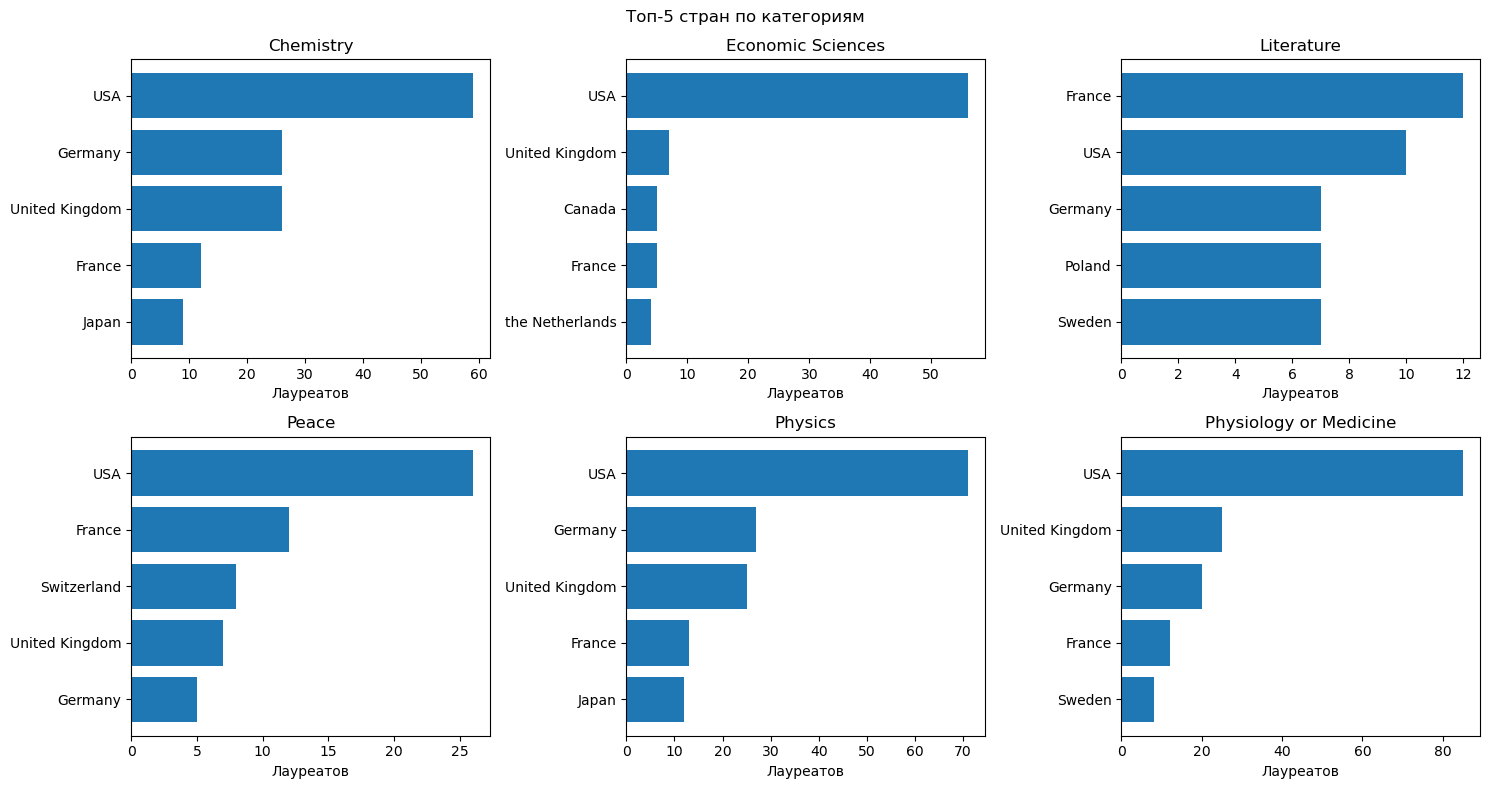

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (category, ranking) in zip(axes.flat, country_category_top.items()):
    ax.barh(
        [row["country"] for row in reversed(ranking)],
        [row["count"] for row in reversed(ranking)],
    )
    ax.set(title=category, xlabel="Лауреатов")
fig.suptitle("Топ-5 стран по категориям")
fig.tight_layout()
plt.show()

**Вывод:**

США лидируют в пяти категориях, Франция: в литературе.

In [15]:
country_decade_top = {}
for decade in decades:
    records = filter_records(award_data, lambda row: row["decade"] == decade)
    country_decade_top[decade] = country_ranking(records)
for decade, ranking in country_decade_top.items():
    print(f"\n{decade}-е")
    country_width = max([len("Страна")] + [len(row["country"]) for row in ranking])
    print(f"{'Место':>5}  {'Страна':<{country_width}}  {'Лауреатов':>9}")
    for position, row in enumerate(ranking, 1):
        print(f"{position:>5}  {row['country']:<{country_width}}  {row['count']:>9}")



1900-е
Место  Страна       Лауреатов
    1  France               9
    2  Germany              8
    3  Poland               5
    4  Italy                4
    5  Switzerland          4

1910-е
Место  Страна   Лауреатов
    1  France           6
    2  Germany          6
    3  Belgium          3
    4  Poland           3
    5  Sweden           3

1920-е
Место  Страна          Лауреатов
    1  Germany                10
    2  France                  8
    3  United Kingdom          7
    4  Denmark                 4
    5  USA                     4

1930-е
Место  Страна          Лауреатов
    1  USA                    14
    2  United Kingdom         10
    3  Germany                 8
    4  Austria                 4
    5  France                  3

1940-е
Место  Страна          Лауреатов
    1  USA                    14
    2  United Kingdom          4
    3  Germany                 3
    4  Switzerland             3
    5  Czech Republic          2

1950-е
Место  Страна         

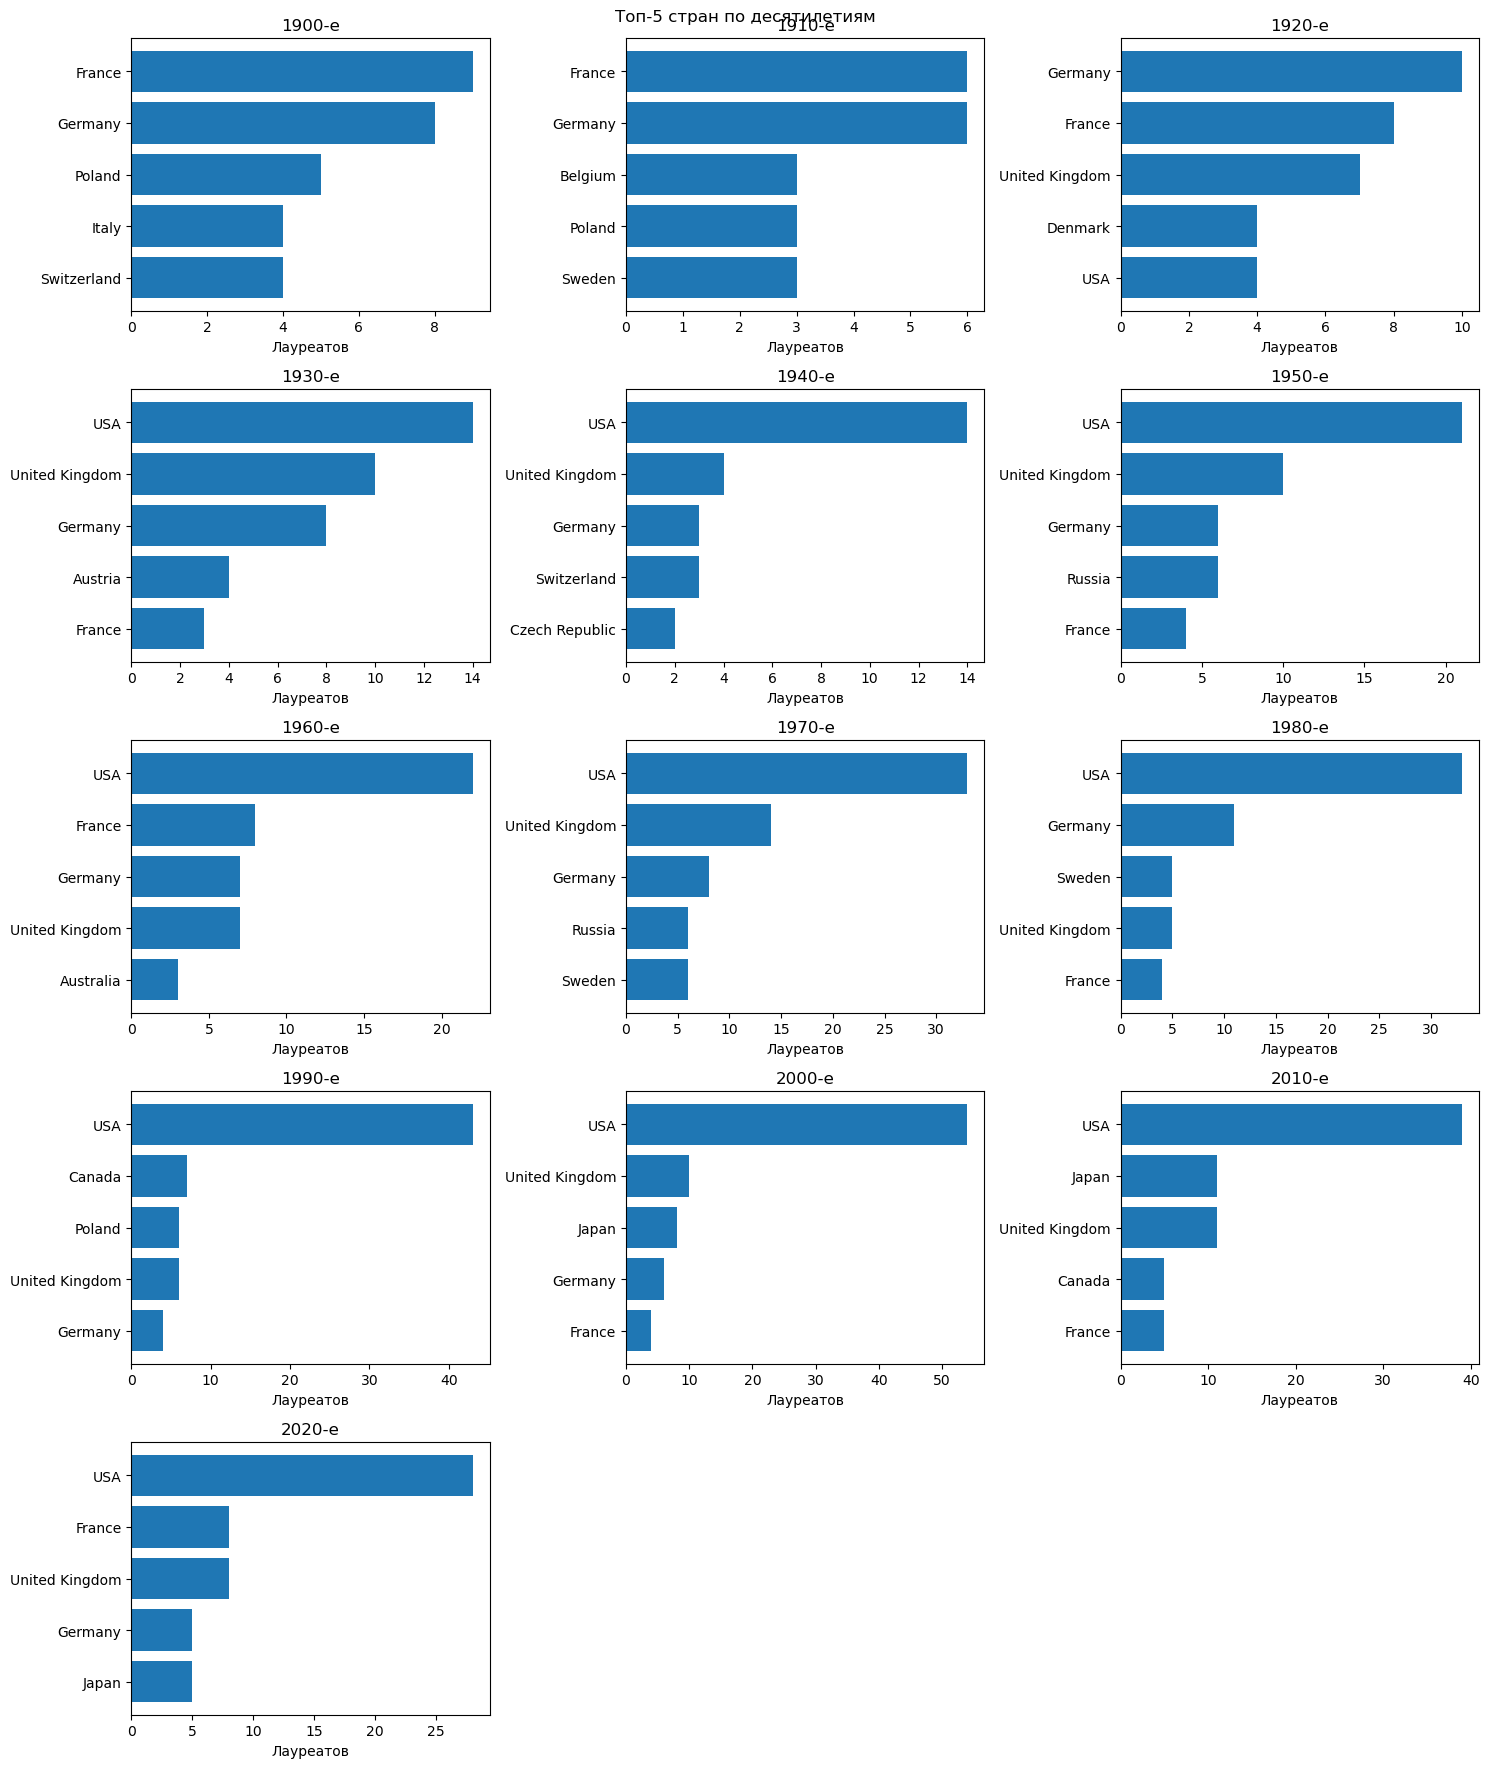

In [16]:
fig, axes = plt.subplots(5, 3, figsize=(15, 18))
for ax, (decade, ranking) in zip(axes.flat, country_decade_top.items()):
    ax.barh(
        [row["country"] for row in reversed(ranking)],
        [row["count"] for row in reversed(ranking)],
    )
    ax.set(title=f"{decade}-е", xlabel="Лауреатов")
for ax in list(axes.flat)[len(country_decade_top):]:
    ax.set_visible(False)
fig.suptitle("Топ-5 стран по десятилетиям")
fig.tight_layout()
plt.show()

**Вывод:**

В начале периода лидировали Франция и Германия. С 1930-х первое место занимают США.

### 2.2. Возраст при награждении

Возраст первого награждения: разница года первого приза и года рождения, записи с пропусками этих годов исключаем, при нескольких категориях в первом году учитываем человека в каждой категории.

In [18]:
persons = filter_records(laureates_data, lambda row: row["type_"] == "person")
persons = add_attribute(persons, "first_award_year", get_first_award_year)
persons = add_attribute(persons, "first_categories", get_first_categories)
age_data = filter_records(persons, lambda row: row["birth_year"] is not None and row["first_award_year"] is not None)
age_data = add_attribute(age_data, "age_first_award", lambda row: row["first_award_year"] - row["birth_year"])
age_data = add_attribute(age_data, "decade", lambda row: row["first_award_year"] // 10 * 10)


def age_metrics(records):
    return {
        "mean": mean_value(records, "age_first_award"),
        "median": median_value(records, "age_first_award"),
    }

In [18]:
age_total = age_metrics(age_data)
print(f"{'Показатель':<10}  {'Возраст, лет':>12}")
for label, value in [("Среднее", age_total["mean"]), ("Медиана", age_total["median"])]:
    print(f"{label:<10}  {value:>12.2f}")


Показатель  Возраст, лет
Среднее            60.61
Медиана            61.00


In [19]:
first_category_data = []
for person in age_data:
    for category in person["first_categories"]:
        first_category_data.append({**person, "category": category})

age_by_category = aggregate_groups(group_by_attributes(first_category_data, ["category"]), age_metrics)
category_width = max([len("Категория первого приза")] + [len(category) for (category,) in age_by_category])
print(f"{'Категория первого приза':<{category_width}}  {'Среднее, лет':>12}  {'Медиана, лет':>12}")
for (category,), metrics in sorted(age_by_category.items()):
    print(f"{category:<{category_width}}  {metrics['mean']:>12.2f}  {metrics['median']:>12.2f}")


Категория первого приза  Среднее, лет  Медиана, лет
Chemistry                       59.43         58.00
Economic Sciences               67.21         67.00
Literature                      65.04         67.00
Peace                           60.97         62.00
Physics                         57.79         56.00
Physiology or Medicine          59.02         58.00


**Вывод:**

Самый низкий средний возраст: в физике (57,79 года), самый высокий: в экономических науках (67,21 года).

In [20]:
age_by_decade = aggregate_groups(group_by_attributes(age_data, ["decade"]), age_metrics)
print(f"{'Десятилетие':<11}  {'Среднее, лет':>12}  {'Медиана, лет':>12}")
for (decade,), metrics in sorted(age_by_decade.items()):
    print(f"{str(decade) + '-е':<11}  {metrics['mean']:>12.2f}  {metrics['median']:>12.2f}")


Десятилетие  Среднее, лет  Медиана, лет
1900-е              57.84         58.00
1910-е              53.08         50.00
1920-е              54.98         56.00
1930-е              51.62         49.00
1940-е              58.02         56.00
1950-е              54.32         54.00
1960-е              56.45         57.00
1970-е              59.34         59.00
1980-е              60.54         60.00
1990-е              62.14         62.00
2000-е              65.87         64.00
2010-е              66.85         69.00
2020-е              69.38         69.00


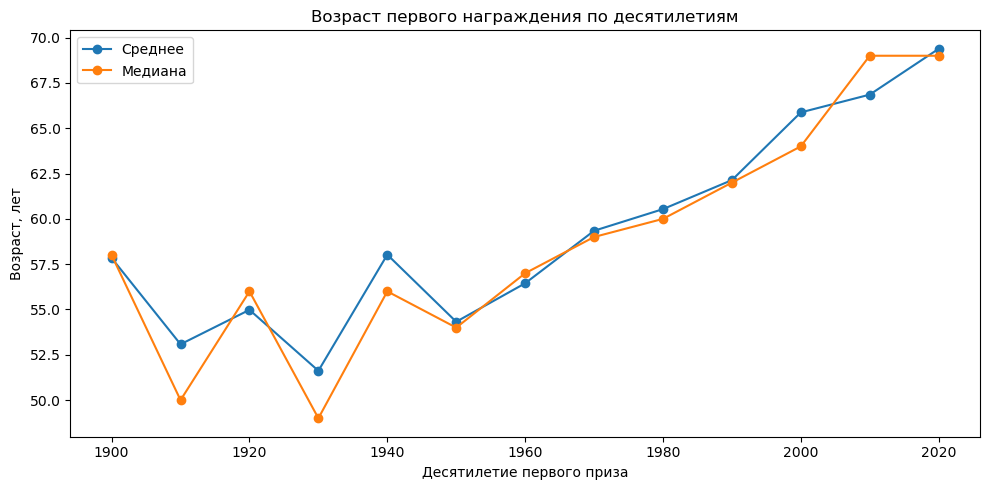

In [21]:
age_decades = sorted(age_by_decade)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    [decade for (decade,) in age_decades],
    [age_by_decade[key]["mean"] for key in age_decades],
    marker="o", label="Среднее",
)
ax.plot(
    [decade for (decade,) in age_decades],
    [age_by_decade[key]["median"] for key in age_decades],
    marker="o", label="Медиана",
)
ax.set(
    title="Возраст первого награждения по десятилетиям",
    xlabel="Десятилетие первого приза", ylabel="Возраст, лет",
)
ax.legend()
fig.tight_layout()
plt.show()

**Вывод:**

Средний возраст вырос с 57,84 года в 1900-х до 69,38 года в 2020-х. Рост не был непрерывным; последнее десятилетие представлено не полностью.

In [22]:
age_by_category_decade = aggregate_groups(group_by_attributes(first_category_data, ["category", "decade"]), age_metrics)
for category in categories:
    print(f"\n{category}")
    print(f"{'Десятилетие':<11}  {'Среднее, лет':>12}  {'Медиана, лет':>12}")
    for (record_category, decade), metrics in sorted(age_by_category_decade.items()):
        if record_category == category:
            print(f"{str(decade) + '-е':<11}  {metrics['mean']:>12.2f}  {metrics['median']:>12.2f}")



Chemistry
Десятилетие  Среднее, лет  Медиана, лет
1900-е              51.00         50.00
1910-е              49.71         47.00
1920-е              52.30         53.00
1930-е              46.00         48.00
1940-е              54.44         55.00
1950-е              53.00         51.50
1960-е              55.80         52.00
1970-е              61.93         60.00
1980-е              55.95         54.00
1990-е              63.11         62.00
2000-е              64.96         64.00
2010-е              71.15         72.00
2020-е              64.76         62.00

Economic Sciences
Десятилетие  Среднее, лет  Медиана, лет
1960-е              70.00         70.00
1970-е              67.00         67.00
1980-е              67.90         67.00
1990-е              65.47         65.00
2000-е              66.85         63.50
2010-е              66.50         67.50
2020-е              69.65         69.00

Literature
Десятилетие  Среднее, лет  Медиана, лет
1900-е              64.90         66.5

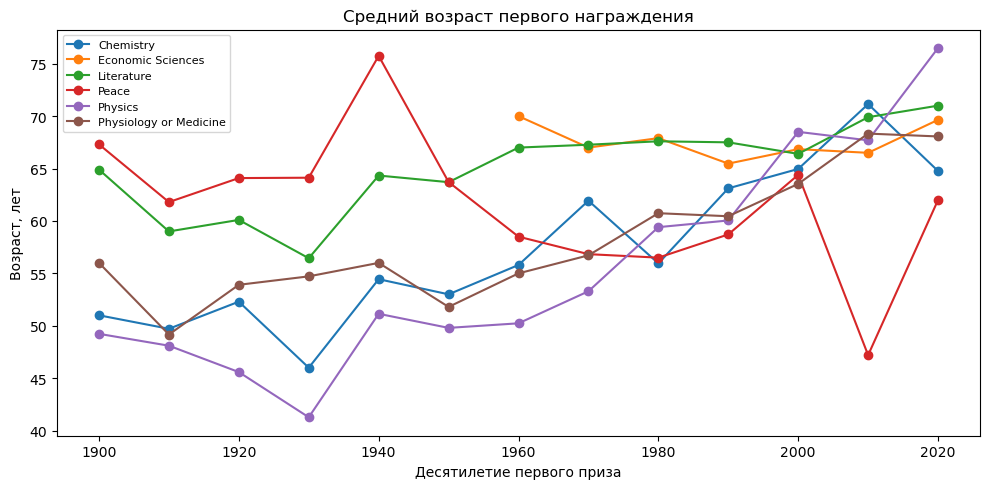

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))
for category in categories:
    points = [(decade, age_by_category_decade[(category, decade)]["mean"]) for decade in decades if (category, decade) in age_by_category_decade]
    ax.plot([point[0] for point in points], [point[1] for point in points], marker="o", label=category)
ax.set(title="Средний возраст первого награждения", xlabel="Десятилетие первого приза", ylabel="Возраст, лет")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 2.3. Гендерное распределение

Сравниваем количество женщин-лауреатов по категориям и десятилетиям. Если женщина получила несколько премий в одной категории за одно десятилетие, считаем её один раз. Сравниваем категории в начале периода (1900-е) и за последние 20 лет набора данных (2007-2026).


In [24]:
women_awards = filter_records(award_data, lambda row: row["gender"] == "female")
women_total = count_records(unique_records(women_awards, ["id"]))
print("Всего женщин-лауреатов:", women_total)

Всего женщин-лауреатов: 69


In [25]:
women_by_category = aggregate_groups(
    group_by_attributes(unique_records(women_awards, ["id", "category"]), ["category"]), count_records
)
category_width = max([len("Категория")] + [len(category) for category in categories])
print(f"{'Категория':<{category_width}}  {'Женщин за все годы':>18}")
for category in categories:
    print(f"{category:<{category_width}}  {women_by_category.get((category,), 0):>18}")


Категория               Женщин за все годы
Chemistry                                8
Economic Sciences                        3
Literature                              19
Peace                                   21
Physics                                  5
Physiology or Medicine                  14


**Вывод:**

Всего в наборе 69 женщин-лауреатов. Больше всего женщин в премии мира (21) и литературе (19).

In [26]:
women_by_decade = aggregate_groups(
    group_by_attributes(unique_records(women_awards, ["id", "decade"]), ["decade"]), count_records
)
print(f"{'Десятилетие':<11}  {'Женщин-лауреатов':>16}")
for decade in decades:
    print(f"{str(decade) + '-е':<11}  {women_by_decade.get((decade,), 0):>16}")


Десятилетие  Женщин-лауреатов
1900-е                      3
1910-е                      1
1920-е                      2
1930-е                      3
1940-е                      3
1950-е                      0
1960-е                      3
1970-е                      4
1980-е                      4
1990-е                      7
2000-е                     11
2010-е                     13
2020-е                     16


In [27]:
women_by_category_decade = aggregate_groups(
    group_by_attributes(unique_records(women_awards, ["id", "category", "decade"]), ["category", "decade"]), count_records
)
for category in categories:
    print(f"\n{category}")
    print(f"{'Десятилетие':<11}  {'Женщин-лауреатов':>16}")
    for decade in decades:
        print(f"{str(decade) + '-е':<11}  {women_by_category_decade.get((category, decade), 0):>16}")



Chemistry
Десятилетие  Женщин-лауреатов
1900-е                      0
1910-е                      1
1920-е                      0
1930-е                      1
1940-е                      0
1950-е                      0
1960-е                      1
1970-е                      0
1980-е                      0
1990-е                      0
2000-е                      1
2010-е                      1
2020-е                      3

Economic Sciences
Десятилетие  Женщин-лауреатов
1900-е                      0
1910-е                      0
1920-е                      0
1930-е                      0
1940-е                      0
1950-е                      0
1960-е                      0
1970-е                      0
1980-е                      0
1990-е                      0
2000-е                      1
2010-е                      1
2020-е                      1

Literature
Десятилетие  Женщин-лауреатов
1900-е                      1
1910-е                      0
1920-е                      

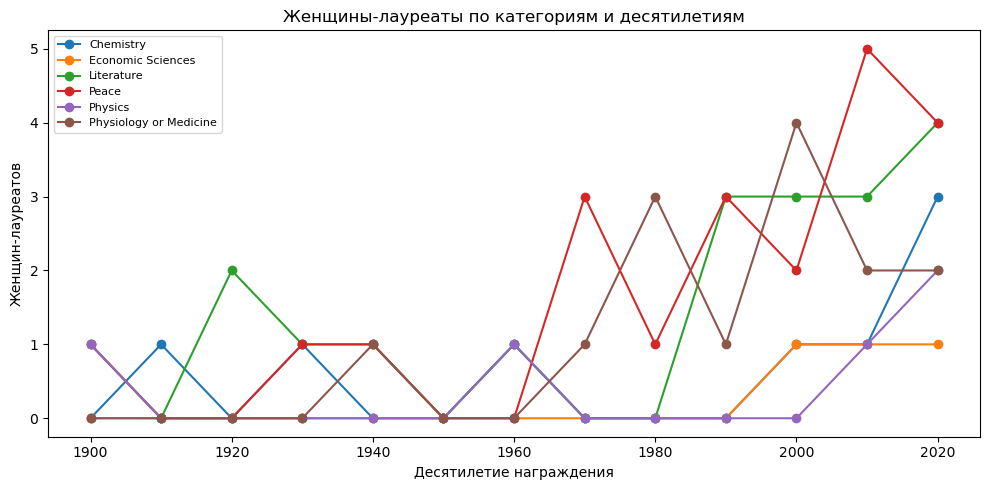

In [28]:
fig, ax = plt.subplots(figsize=(10, 5))
for category in categories:
    ax.plot(decades, [women_by_category_decade.get((category, decade), 0) for decade in decades], marker="o", label=category)
ax.set(title="Женщины-лауреаты по категориям и десятилетиям", xlabel="Десятилетие награждения", ylabel="Женщин-лауреатов")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Вывод:**

В 2000-х награждены 11 женщин, в 2010-х: 13, в неполных 2020-х: 16.

In [29]:
def women_category_leaders(records):
    counts = aggregate_groups(
        group_by_attributes(unique_records(records, ["id", "category"]), ["category"]), count_records
    )
    if not counts:
        return []
    largest = max(counts.values())
    return [(category, count) for (category,), count in sorted(counts.items()) if count == largest]


first_women_decade = min(row["decade"] for row in women_awards)
recent_start = last_year - 19
initial_women = filter_records(women_awards, lambda row: row["decade"] == first_women_decade)
recent_women = filter_records(women_awards, lambda row: recent_start <= row["award_year"] <= last_year)
initial_leaders = women_category_leaders(initial_women)
recent_leaders = women_category_leaders(recent_women)
for period, leaders in [
    (f"Первое десятилетие: {first_women_decade}-е", initial_leaders),
    (f"Последние 20 лет: {recent_start}-{last_year}", recent_leaders),
]:
    print(f"\n{period}")
    category_width = max([len("Категория")] + [len(category) for category, count in leaders])
    print(f"{'Категория':<{category_width}}  {'Женщин-лауреатов':>16}")
    for category, count in leaders:
        print(f"{category:<{category_width}}  {count:>16}")



Первое десятилетие: 1900-е
Категория   Женщин-лауреатов
Literature                 1
Peace                      1
Physics                    1

Последние 20 лет: 2007-2026
Категория   Женщин-лауреатов
Literature                 9
Peace                      9


**Вывод:**

В 1900-х по одной женщине награждено в физике, литературе и премии мира. За 2007-2026 лидируют литература и премия мира: по 9 женщин.

---------

## Бонусное задание на +2 балла


### Лингвистический анализ мотиваций**

**5.1. Анализ текстов мотиваций**
- Соберите корпус текстов мотиваций вручения премий. Для этого измените конфиг обработки призов.
- Выделите самые частые топ-50 слов. Какие из этих слов самые частые в принципе в английском языке (такие, как for, the и другие), а какие кажутся важными именно в контексте вручения Нобелевской премии (например, 'chemistry')?
- Самые частые слова, которые также являются частыми во всем английском языке занесите в отдельный конфиг-файл под названием `stopwords.py`. Вычистите их из текстов. Какие слова являются самыми частыми теперь? Сравните множества топ-10 самых частых слов по разным категориям


- Если есть желание, посчитайте TF-IDF + сравнените топ слов по этой метрике с просто самыми популярными словами)